In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from mpl_toolkits.axes_grid1 import make_axes_locatable
from scipy.stats import binned_statistic_2d, qmc
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.covariance import ledoit_wolf
from pathlib import Path
from jcamp import readfile
import pickle
import yaml

In [2]:
from setup import (
    white,
    black,
    colors,
    plot_style,
    filepath,
    training_labels,
    spectral_range,
    absorption_path_length,
    training_settling_time as settling_time,
    calibration_type,
    predictor_type,
    concentration_bin_width,
    synthetic_sample_ratio,
    number_folds,
    random_seed,
)
from processing import (
    is_system_settled,
    center_spectra,
    broaden_spectrum,
    scaling_from_pid_to_cell,
    annotate,
    format_number,
)

In [3]:
plt.style.use(plot_style)

rng = np.random.RandomState(random_seed)

### Load training datasets

In [4]:
times = []
voltages = []
spectral_predictors = []
flowrates = []
setpoints = []
are_settled = []
are_analyte_free = []

wavenumber = None
spectral_resolution = None
gas_1 = None
gas_2 = None
split_ratio = None
window_type = None
correction_type = None
signal_type = None

for label in training_labels:
    dataset = np.load(filepath / f"{label}.npz")
    metadata = yaml.safe_load((filepath / f"{label}.yaml").read_text())

    if spectral_resolution is None:
        spectral_resolution = metadata["sampling"]["spectral_resolution"]
    elif spectral_resolution != metadata["sampling"]["spectral_resolution"]:
        raise ValueError(f"Spectral resolution mismatch for {label}.")

    time = dataset["time"]
    spectrum = dataset["spectrum"]

    if wavenumber is None:
        wavenumber = dataset["wavenumber"]
        spectral_mask = (wavenumber >= spectral_range[0]) & (
            wavenumber <= spectral_range[1]
        )
    elif wavenumber.shape != dataset["wavenumber"].shape:
        raise ValueError(f"Wavenumber mismatch for {label}.")
    elif not np.allclose(wavenumber, dataset["wavenumber"], atol=1e-3):
        raise ValueError(f"Wavenumber mismatch for {label}.")

    if gas_1 is None:
        gas_1 = str(dataset["gas_1"])
    elif gas_1 != str(dataset["gas_1"]):
        raise ValueError(f"Gas 1 mismatch for {label}.")

    if gas_2 is None:
        gas_2 = str(dataset["gas_2"])
    elif gas_2 != str(dataset["gas_2"]):
        raise ValueError(f"Gas 2 mismatch for {label}.")

    if split_ratio is None:
        split_ratio = float(dataset["split_ratio"])
    elif split_ratio != float(dataset["split_ratio"]):
        raise ValueError(f"Split ratio mismatch for {label}.")

    if dataset["type"] == "twins":
        if window_type is None:
            window_type = str(dataset["window_type"])
        elif window_type != str(dataset["window_type"]):
            raise ValueError(f"Window type mismatch for {label}.")

        if correction_type is None:
            correction_type = str(dataset["correction_type"])
        elif correction_type != str(dataset["correction_type"]):
            raise ValueError(f"Correction type mismatch for {label}.")

        if signal_type is None:
            signal_type = str(dataset["signal_type"])
        elif signal_type != str(dataset["signal_type"]):
            raise ValueError(f"Signal type mismatch for {label}.")

    setpoint_0 = dataset["setpoint_0"]
    setpoint_1 = dataset["setpoint_1"]
    setpoint_2 = dataset["setpoint_2"]
    setpoint = np.stack(
        [
            np.mean(setpoint_0, axis=1),
            np.mean(setpoint_1, axis=1),
            np.mean(setpoint_2, axis=1),
        ],
        axis=1,
    )

    flowrate_0 = dataset["flowrate_0"]
    flowrate_1 = dataset["flowrate_1"]
    flowrate_2 = dataset["flowrate_2"]
    flowrate = np.stack(
        [
            np.mean(flowrate_0, axis=1),
            np.mean(flowrate_1, axis=1),
            np.mean(flowrate_2, axis=1),
        ],
        axis=1,
    )

    voltage_pid_1 = dataset["voltage_pid_1"] / 1e6  # (V)
    voltage_pid_2 = dataset["voltage_pid_2"] / 1e6  # (V)
    voltage = np.stack(
        [np.mean(voltage_pid_1, axis=1), np.mean(voltage_pid_2, axis=1)],
        axis=1,
    )

    time_offset = np.max(np.concatenate(times)) if times else 0
    time = np.min(time, axis=1) + time_offset

    spectrum = spectrum[:, spectral_mask]

    is_settled = is_system_settled(time, setpoint_1, setpoint_2, settling_time)
    is_analyte_free = (
        np.all((setpoint_0 != 0) & (setpoint_1 == 0) & (setpoint_2 == 0), axis=1)
        & is_settled
    )

    if not np.any(is_analyte_free):
        raise ValueError(f"No analyte-free spectra found for {label}.")

    if predictor_type == "absorbance":
        spectral_predictor = -np.log10(
            spectrum / np.mean(spectrum[is_analyte_free, :], axis=0)
        )
    elif predictor_type == "neg-log-spectrum":
        spectral_predictor = -np.log10(spectrum)

    times.append(time)
    voltages.append(voltage)
    spectral_predictors.append(spectral_predictor)
    flowrates.append(flowrate)
    setpoints.append(setpoint)
    are_settled.append(is_settled)
    are_analyte_free.append(is_analyte_free)

times = np.concatenate(times, axis=0)
voltages = np.concatenate(voltages, axis=0)
spectral_predictors = np.concatenate(spectral_predictors, axis=0)
flowrates = np.concatenate(flowrates, axis=0)
setpoints = np.concatenate(setpoints, axis=0)
are_settled = np.concatenate(are_settled, axis=0)
are_analyte_free = np.concatenate(are_analyte_free, axis=0)

gases = (gas_1, gas_2)
wavenumber = wavenumber[spectral_mask]

In [5]:
number_spectra, number_wavenumbers = np.shape(spectral_predictors)
number_gases = len(gases)
gas_pair = "-".join(gas.lower() for gas in gases)

print(f"Datasets: {', '.join(training_labels)}")
print(f"Gases: {gas_1.capitalize()}, {gas_2.capitalize()}")
print(
    f"Spectra: {number_spectra} "
    f"({np.sum(are_settled)} are settled, {np.sum(are_analyte_free)} are analyte free)"
)
print(f"Wavenumbers: {number_wavenumbers} at {spectral_resolution} cm^-1 resolution")

Datasets: GRASP26_71F
Gases: Isopropanol, Ethanol
Spectra: 882 (402 are settled, 210 are analyte free)
Wavenumbers: 30 at 20 cm^-1 resolution


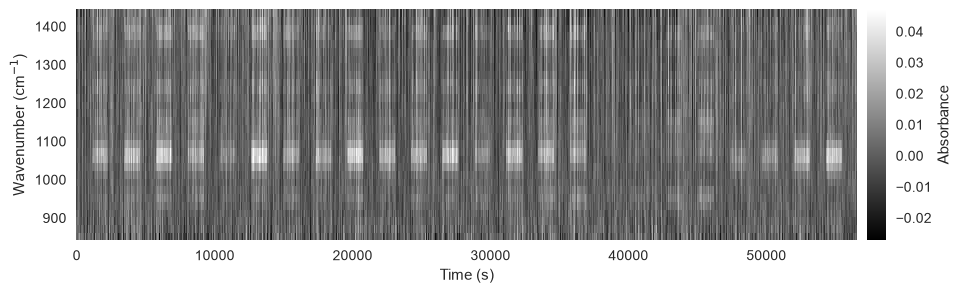

In [6]:
fig, ax = plt.subplots(figsize=(12, 3))

mesh = ax.pcolormesh(
    times,
    wavenumber,
    spectral_predictors.T,
    cmap="gray",
)

ax.set_xlabel("Time (s)")
ax.set_ylabel("Wavenumber (cm$^{-1}$)")

fig.colorbar(mesh, ax=ax, label=predictor_type.capitalize(), aspect=12, pad=0.01)

### Load calibrated concentrations

In [7]:
concentrations = []
cutoff_concentrations = []
scalings_pid_to_cell = []
for ii, gas in enumerate(gases):
    with open(Path("models", f"estimator-{gas.lower()}.pkl"), "rb") as file:
        calibration = pickle.load(file)

    concentration_estimator = calibration["estimator"]

    if calibration_type == "flowrate":
        concentration = concentration_estimator(flowrates[:, ii + 1])
    elif calibration_type == "pid":
        scaling_pid_to_cell = scaling_from_pid_to_cell(flowrates, split_ratio, ii + 1)
        concentration = scaling_pid_to_cell * concentration_estimator(voltages[:, ii])

        cutoff_concentrations.append(calibration["cutoff_concentration"])
        scalings_pid_to_cell.append(scaling_pid_to_cell)

    concentrations.append(concentration)

concentrations = np.stack(concentrations, axis=1)
if calibration_type == "pid":
    cutoff_concentrations = np.array(cutoff_concentrations)
    scalings_pid_to_cell = np.stack(scalings_pid_to_cell, axis=1)

### Select training samples

In [8]:
selection_mask = are_settled
if calibration_type == "pid":
    selection_mask = selection_mask & np.all(
        concentrations < cutoff_concentrations * scalings_pid_to_cell,
        axis=1,
    )

spectral_predictors_selected = spectral_predictors[selection_mask]
concentrations_selected = concentrations[selection_mask]

In [9]:
wavenumber_nist = {}
absorption_coefficients_nist = {}
absorption_coefficients = []
for gas in gases:
    data_nist = readfile(Path("NIST", f"{gas}.jdx"))

    if data_nist["yunits"] == "TRANSMITTANCE":
        data_nist["y"] = -np.log10(data_nist["y"])

    wavenumber_nist[gas] = data_nist["x"]
    absorption_coefficients_nist[gas] = broaden_spectrum(
        data_nist["x"],
        data_nist["y"],
        spectral_range,
        spectral_resolution,
        window_type,
    )

    spectral_mask_nist = (wavenumber_nist[gas] >= spectral_range[0]) & (
        wavenumber_nist[gas] <= spectral_range[1]
    )
    wavenumber_nist[gas] = wavenumber_nist[gas][spectral_mask_nist]
    absorption_coefficients_nist[gas] = absorption_coefficients_nist[gas][
        spectral_mask_nist
    ]

    absorption_coefficients.append(
        np.interp(wavenumber, wavenumber_nist[gas], absorption_coefficients_nist[gas])
    )

absorption_coefficients = np.stack(absorption_coefficients, axis=1)

In [10]:
if predictor_type == "absorbance" and synthetic_sample_ratio > 0:
    if calibration_type == "pid":
        number_samples = np.sum(selection_mask)
        number_synthetic_samples = int(
            np.round(
                synthetic_sample_ratio / (1 - synthetic_sample_ratio) * number_samples
            )
        )

        sampler = qmc.Sobol(
            d=number_gases,
            scramble=True,
            rng=rng.randint(2**31 - 1),
        )
        concentrations_synthetic = qmc.scale(
            sampler.random(number_synthetic_samples),
            np.zeros(number_gases),
            cutoff_concentrations,
        )

        absorbances_synthetic = (
            concentrations_synthetic
            @ absorption_coefficients.T
            * absorption_path_length
        )

        noise_covariance, _ = ledoit_wolf(spectral_predictors[are_analyte_free, :])

        noise = (
            rng.normal(size=(number_synthetic_samples, number_wavenumbers))
            @ np.linalg.cholesky(noise_covariance).T
        )
        absorbances_synthetic += noise

        is_synthetic = np.concatenate(
            [
                np.zeros(number_samples, dtype=bool),
                np.ones(number_synthetic_samples, dtype=bool),
            ]
        )

        spectral_predictors_selected = np.concatenate(
            [spectral_predictors_selected, absorbances_synthetic], axis=0
        )
        concentrations_selected = np.concatenate(
            [concentrations_selected, concentrations_synthetic], axis=0
        )

C:\Users\eherkert\AppData\Local\Temp\ipykernel_3980\3268583128.py:16: UserWarning: The balance properties of Sobol' points require n to be a power of 2.
  sampler.random(number_synthetic_samples),


In [11]:
if concentration_bin_width is not None:
    number_bins = np.ceil(
        np.max(concentrations_selected, axis=0) / concentration_bin_width
    ).astype(int)
else:
    number_bins = (10, 10)

*_, bin_ids = binned_statistic_2d(
    concentrations_selected[:, 0],
    concentrations_selected[:, 1],
    values=None,
    statistic="count",
    bins=number_bins,
)

sample_weights = 1.0 / pd.Series(bin_ids).groupby(bin_ids).transform("size").to_numpy()
sample_weights /= sample_weights.sum()

print(
    f"Training samples: {len(concentrations_selected)} "
    f"in {number_bins[0]} x {number_bins[1]} concentration bins"
)
if (
    predictor_type == "absorbance"
    and calibration_type == "pid"
    and synthetic_sample_ratio > 0
):
    print(
        f"Synthetic samples: {is_synthetic.mean() * 100:.1f}% of samples, "
        f"{sample_weights[is_synthetic].sum() * 100:.1f}% of training weight"
    )

Training samples: 502 in 1071 x 1892 concentration bins
Synthetic samples: 19.9% of samples, 69.9% of training weight


### Train regression model

In [12]:
cross_validation = KFold(n_splits=number_folds, shuffle=True, random_state=rng)

pipeline = Pipeline(
    [
        (
            "centerer",
            FunctionTransformer(center_spectra),
        ),
        (
            "scaler",
            StandardScaler(with_std=False),
        ),
        (
            "model",
            Ridge(fit_intercept=True, tol=1e-6, max_iter=5_000),
        ),
    ]
)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid={"model__alpha": np.logspace(-10, 0, 201)},
    cv=cross_validation,
    scoring="neg_mean_squared_error",
)

grid_search.fit(
    spectral_predictors_selected,
    concentrations_selected,
    model__sample_weight=sample_weights,
)

model = grid_search.best_estimator_

print(f"Best alpha: {grid_search.best_params_['model__alpha']:.3g}")
print(f"Cross-validated RMSE: {np.sqrt(-grid_search.best_score_):.1f} ppm")

Best alpha: 8.91e-06
Cross-validated RMSE: 153.9 ppm


In [13]:
path = Path("models", f"ridge-{gas_pair}.pkl")

with open(path, "wb") as file:
    pickle.dump(model, file)

print(f"Saved: {path}")

Saved: models\ridge-isopropanol-ethanol.pkl


### Inspect regression model

In [14]:
concentrations_predicted = model.predict(spectral_predictors)

predictors = np.concatenate(
    [concentrations[selection_mask, :], np.ones((np.sum(selection_mask), 1))], axis=1
)
fits = [
    sm.OLS(concentrations_predicted[selection_mask, ii], predictors).fit()
    for ii in range(number_gases)
]

sensitivities = np.stack([fit.params[:number_gases] for fit in fits])
sensitivities_se = np.stack([fit.bse[:number_gases] for fit in fits])
biases = np.array([fit.params[number_gases] for fit in fits])
biases_se = np.array([fit.bse[number_gases] for fit in fits])

sigmas = np.std(concentrations_predicted[are_analyte_free, :], axis=0, ddof=1)
sigmas_se = sigmas / np.sqrt(2 * (np.sum(are_analyte_free) - 1))

for ii, gas in enumerate(gases):
    sensitivity = sensitivities[ii, ii]
    limit_of_detection = 3 * sigmas[ii] / sensitivity
    limit_of_detection_se = limit_of_detection * np.sqrt(
        sigmas_se[ii] ** 2 / sigmas[ii] ** 2
        + sensitivities_se[ii, ii] ** 2 / sensitivity**2
    )

    print(
        f"{gas.capitalize()}: "
        f"sensitivity = {sensitivity:.3f} +/- {sensitivities_se[ii, ii]:.3f}, "
        f"cross-sensitivity = {sensitivities[ii, 1 - ii]:+.3f} +/- "
        f"{sensitivities_se[ii, 1 - ii]:.3f} ({gases[1 - ii].capitalize()})"
    )
    print(
        f"{gas.capitalize()}: "
        f"bias = {biases[ii]:.0f} +/- {biases_se[ii]:.0f} ppm, "
        f"standard dev. = {sigmas[ii]:.0f} +/- {sigmas_se[ii]:.0f} ppm, "
        f"LOD = {limit_of_detection:.0f} +/- {limit_of_detection_se:.0f} ppm"
    )

Isopropanol: sensitivity = 1.025 +/- 0.033, cross-sensitivity = -0.012 +/- 0.022 (Ethanol)
Isopropanol: bias = 4 +/- 11 ppm, standard dev. = 163 +/- 8 ppm, LOD = 478 +/- 28 ppm
Ethanol: sensitivity = 0.986 +/- 0.017, cross-sensitivity = -0.002 +/- 0.026 (Isopropanol)
Ethanol: bias = 5 +/- 9 ppm, standard dev. = 128 +/- 6 ppm, LOD = 391 +/- 20 ppm


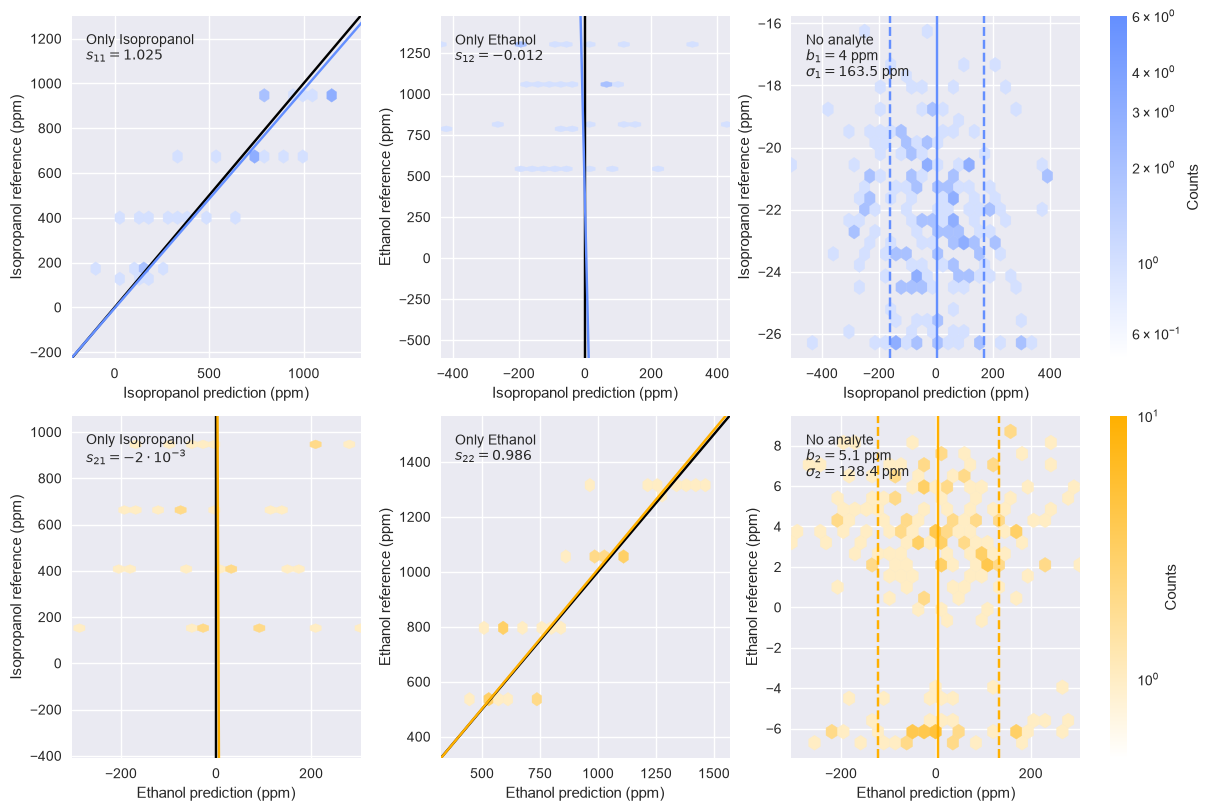

In [15]:
only_gas_masks = []
for ii in range(number_gases):
    other_gases = [jj + 1 for jj in range(number_gases) if jj != ii]
    only_gas_masks.append(
        selection_mask
        & (setpoints[:, ii + 1] != 0)
        & np.all(setpoints[:, other_gases] == 0, axis=1)
    )

fig, axs = plt.subplots(
    number_gases,
    number_gases + 1,
    figsize=(4 * (number_gases + 1), 4 * number_gases),
    constrained_layout=True,
    squeeze=False,
)

hexbin_kwargs = {"gridsize": 25, "mincnt": 1, "zorder": 5}

for ii, gas in enumerate(gases):
    cmap = LinearSegmentedColormap.from_list(
        f"white_to_{gas}",
        [white, colors[ii]],
    )
    hexbins = []

    ### sensitivity and cross-sensitivity panels ###
    for jj in range(number_gases):
        concentrations_estimated = concentrations_predicted[only_gas_masks[jj], ii]
        concentrations_reference = concentrations[only_gas_masks[jj], jj]

        concentration_minimum = np.min(
            [concentrations_estimated.min(), concentrations_reference.min()]
        )
        concentration_maximum = np.max(
            [concentrations_estimated.max(), concentrations_reference.max()]
        )
        concentration_limits = np.array(
            [
                concentration_minimum
                - 0.1 * (concentration_maximum - concentration_minimum),
                concentration_maximum
                + 0.1 * (concentration_maximum - concentration_minimum),
            ]
        )

        if jj == ii:
            hexbins.append(
                axs[ii, jj].hexbin(
                    concentrations_estimated,
                    concentrations_reference,
                    cmap=cmap,
                    extent=(
                        concentration_minimum,
                        concentration_maximum,
                        concentration_minimum,
                        concentration_maximum,
                    ),
                    **hexbin_kwargs,
                )
            )
            axs[ii, jj].plot(
                concentration_limits,
                concentration_limits,
                color=black,
                zorder=10,
            )
            axs[ii, jj].set_xlim(*concentration_limits)
        else:
            hexbins.append(
                axs[ii, jj].hexbin(
                    concentrations_estimated,
                    concentrations_reference,
                    cmap=cmap,
                    **hexbin_kwargs,
                )
            )
            axs[ii, jj].axvline(0, color=black, zorder=10)
            axs[ii, jj].set_xlim(
                -np.max(np.abs(concentrations_estimated)),
                np.max(np.abs(concentrations_estimated)),
            )

        axs[ii, jj].plot(
            sensitivities[ii, jj] * concentration_limits + biases[ii],
            concentration_limits,
            color=colors[ii],
            zorder=15,
        )

        axs[ii, jj].set_ylim(*concentration_limits)
        axs[ii, jj].set_xlabel(f"{gas.capitalize()} prediction (ppm)")
        axs[ii, jj].set_ylabel(f"{gases[jj].capitalize()} reference (ppm)")

        annotate(
            axs[ii, jj],
            f"Only {gases[jj].capitalize()}\n"
            f"$s_{{{ii + 1}{jj + 1}}} = "
            f"{format_number(sensitivities[ii, jj], sensitivities_se[ii, jj])}$",
        )

    ### bias panel ###
    concentrations_estimated = concentrations_predicted[are_analyte_free, ii]
    concentrations_reference = concentrations[are_analyte_free, ii]

    hexbins.append(
        axs[ii, -1].hexbin(
            concentrations_estimated,
            concentrations_reference,
            cmap=cmap,
            **hexbin_kwargs,
        )
    )

    axs[ii, -1].axvline(biases[ii], color=colors[ii], zorder=10)
    axs[ii, -1].axvline(
        biases[ii] + sigmas[ii], color=colors[ii], linestyle="--", zorder=10
    )
    axs[ii, -1].axvline(
        biases[ii] - sigmas[ii], color=colors[ii], linestyle="--", zorder=10
    )

    axs[ii, -1].margins(0.05, 0.05)
    axs[ii, -1].set_xlim(
        -np.max(np.abs(concentrations_estimated)),
        np.max(np.abs(concentrations_estimated)),
    )
    axs[ii, -1].set_xlabel(f"{gas.capitalize()} prediction (ppm)")
    axs[ii, -1].set_ylabel(f"{gas.capitalize()} reference (ppm)")

    annotate(
        axs[ii, -1],
        f"No analyte\n"
        f"$b_{{{ii + 1}}} = {format_number(biases[ii], biases_se[ii])}$ ppm\n"
        f"$\\sigma_{{{ii + 1}}} = {format_number(sigmas[ii], sigmas_se[ii])}$ ppm",
    )

    ### shared count scale ###
    count_maximum = np.max([hexbin.get_array().max() for hexbin in hexbins])
    normalization = LogNorm(vmin=0.5, vmax=2 * count_maximum)

    for hexbin in hexbins:
        hexbin.set_norm(normalization)

    fig.colorbar(
        hexbins[0],
        ax=axs[ii, :],
        location="right",
        label="Counts",
        aspect=20,
        pad=0.02,
    )

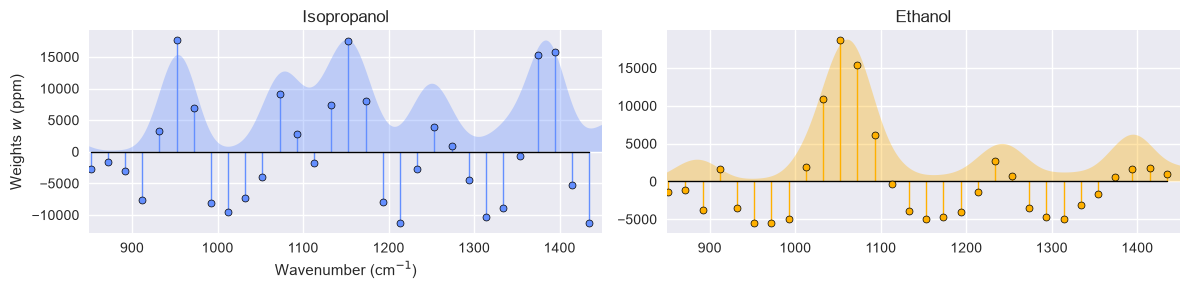

In [16]:
fig, axs = plt.subplots(
    1,
    number_gases,
    figsize=(6 * number_gases, 3),
    sharex=True,
    squeeze=False,
)

for ii, gas in enumerate(gases):
    model_weights = model.named_steps["model"].coef_[ii, :]

    markerline, stemlines, baseline = axs[0, ii].stem(
        wavenumber,
        model_weights,
    )
    plt.setp(stemlines, color=colors[ii], linewidth=1, zorder=10)
    plt.setp(
        markerline,
        markerfacecolor=colors[ii],
        markeredgecolor=black,
        marker="o",
        markersize=5,
        markeredgewidth=0.5,
        zorder=20,
    )
    plt.setp(baseline, color=black, linewidth=1, zorder=15)

    axs[0, ii].fill_between(
        wavenumber_nist[gas],
        np.max(model_weights)
        * absorption_coefficients_nist[gas]
        / np.max(absorption_coefficients_nist[gas]),
        facecolor=colors[ii] + "55",
        zorder=5,
    )

    axs[0, ii].margins(x=0)
    axs[0, ii].set_title(gas.capitalize())

axs[0, 0].set_xlabel("Wavenumber (cm$^{-1}$)")
axs[0, 0].set_ylabel("Weights $w$ (ppm)")

fig.tight_layout()

Isopropanol: training RMSE = 163.7 ppm
Ethanol: training RMSE = 131.5 ppm


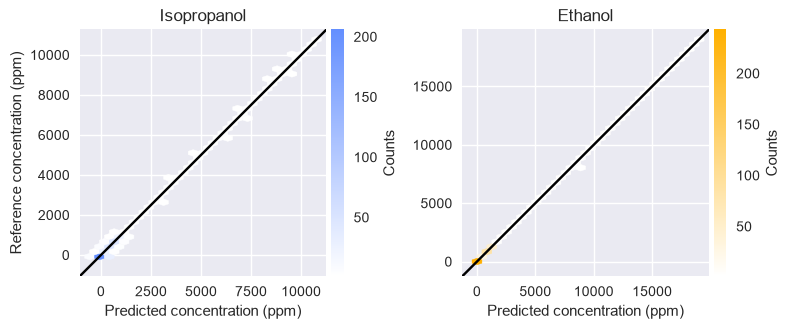

In [17]:
fig, axs = plt.subplots(
    1,
    number_gases,
    figsize=(4 * number_gases, 4),
    squeeze=False,
)

concentrations_predicted_selected = model.predict(spectral_predictors_selected)

for ii, gas in enumerate(gases):
    concentrations_reference = concentrations_selected[:, ii]
    concentrations_estimated = concentrations_predicted_selected[:, ii]

    rmse = np.sqrt(np.mean((concentrations_reference - concentrations_estimated) ** 2))
    print(f"{gas.capitalize()}: training RMSE = {rmse:.1f} ppm")

    concentration_minimum = np.min(
        [concentrations_reference.min(), concentrations_estimated.min()]
    )
    concentration_maximum = np.max(
        [concentrations_reference.max(), concentrations_estimated.max()]
    )
    concentration_limits = [
        concentration_minimum - 0.05 * (concentration_maximum - concentration_minimum),
        concentration_maximum + 0.05 * (concentration_maximum - concentration_minimum),
    ]

    ax = axs[0, ii]
    ax.set_xlim(concentration_limits)
    ax.set_ylim(concentration_limits)

    cmap = LinearSegmentedColormap.from_list(
        f"white_to_{gas}",
        [white, colors[ii]],
    )

    hexbin = ax.hexbin(
        concentrations_estimated,
        concentrations_reference,
        gridsize=(25, 25),
        mincnt=1,
        cmap=cmap,
        extent=(
            concentration_limits[0],
            concentration_limits[1],
            concentration_limits[0],
            concentration_limits[1],
        ),
    )

    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.05)
    fig.colorbar(hexbin, cax=cax, label="Counts")

    ax.plot(
        concentration_limits,
        concentration_limits,
        color=black,
    )

    ax.set_aspect("equal", adjustable="box")
    ax.set_title(gas.capitalize())

for ii in range(number_gases):
    axs[0, ii].set_xlabel("Predicted concentration (ppm)")
axs[0, 0].set_ylabel("Reference concentration (ppm)")

fig.tight_layout()
for ii in range(number_gases):
    axs[0, ii].set_aspect("equal", adjustable="box")

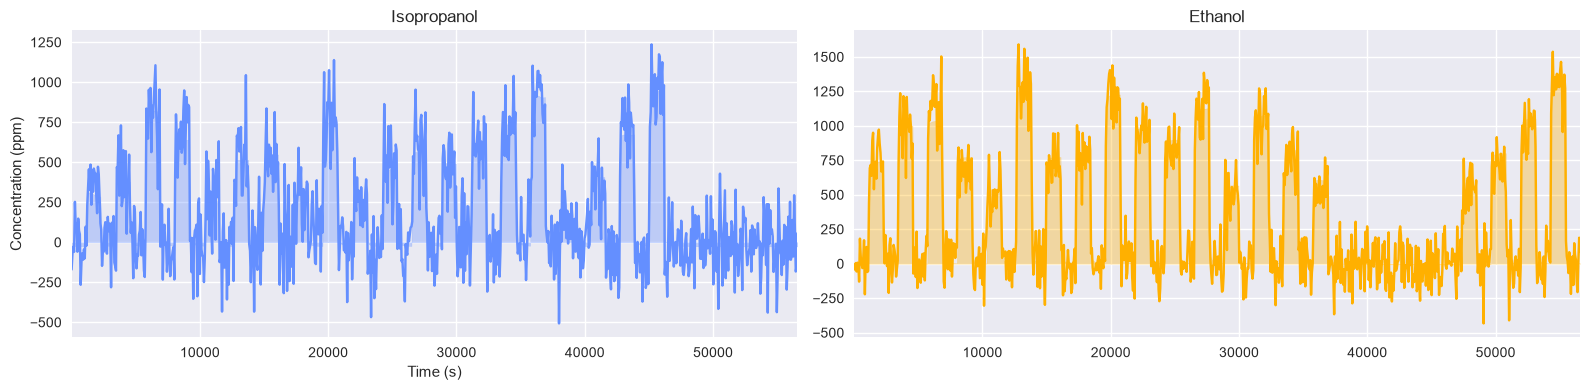

In [18]:
fig, axs = plt.subplots(
    1,
    number_gases,
    figsize=(8 * number_gases, 4),
    squeeze=False,
)

for ii, gas in enumerate(gases):
    axs[0, ii].plot(
        times,
        concentrations_predicted[:, ii],
        color=colors[ii],
        zorder=10,
    )
    axs[0, ii].fill_between(
        times,
        concentrations[:, ii],
        color=colors[ii] + "55",
        zorder=5,
    )

    axs[0, ii].margins(x=0)
    axs[0, ii].set_title(gas.capitalize())

axs[0, 0].set_xlabel("Time (s)")
axs[0, 0].set_ylabel("Concentration (ppm)")

fig.tight_layout()